# Lab 07 – Evaluating Unsupervised Models: When Metrics Disagree

**Data Science Lab 83-554 · Bar-Ilan University · Dr. Alexandra Litinsky Simanovsky**

In the previous lab you chose a clustering and defended it. Today the question is the one behind that choice: **how do you decide that an unsupervised model is good, when different metrics, assumptions and goals disagree?**

**The story.** A field-biology team recorded frog calls in 59 recording sessions. Each session recorded **one calling frog**, with whatever microphone and placement the team had that night. Besides the calls, every session kept a few short **background segments** – the same microphone, no frog calling. The team wants to sort new recordings by species without listening to every one, and asks you which clustering to trust. You will first decide how to normalize the recordings, then compare internal metrics, stability, information criteria and three algorithms, and only then open a taxonomy the biologists kept hidden from you. Finally you will see how a score can improve for the wrong reason, test on sessions the model has never heard, and write them a recommendation.

The goal is not to discover one magic score. A clustering has no single "accuracy", and by the end you will be able to say what each number does and does not tell you.

| Block | Topic | Exercises | Time |
|---|---|---|---|
| 0 | Audit and a first look | 1–2 | ~15 min |
| 1 | Normalize by what? Microphones and recordings | 3–6 | ~35 min |
| 2 | Internal evaluation: K-Means | 7–9 | ~25 min |
| 3 | Stability: does the answer survive re-running? | 10–11 | ~15 min |
| 4 | Other algorithms: GMM, Ward and DBSCAN | 12–15 | ~35 min |
| 5 | Reveal the taxonomy: external evaluation | 16–21 | ~45 min |
| 6 | Leakage and new recording sessions | 22–24 | ~25 min |
| 7 | Find the bug | 25–27 | ~15 min |
| 8 | Integrated challenge: the evaluation report | 28 | ~20 min |
| 9 | Working with an LLM, critically | 29–30 | ~15 min |
| 10 | Further investigations ★ (extra) | 31–33 |  |

Plan: about 245 minutes.

**★ = extra.** Exercises marked ★ (all of Block 10) are extra practice: do them if you finish early. Whatever you do not finish in class, you finish on your own.

**How to work**
- Each exercise shows the **expected output** (a chart, a table, or a description of the result) under an empty cell. Write code that produces it, then run the cell – your output replaces the expected one, so save your own copy and keep the original open.
- Hints are collapsed under each exercise. Try first, open them only if you are stuck.
- Where an exercise says *explain*, write your answer in a short comment or a Markdown cell, in English or Hebrew. A number from your own output is part of a good answer.
- Exercises depend on each other and run **in order, once**: if a result looks strange, restart from the first cell instead of re-running a single cell.
- The first code cell is supplied: imports, `RANDOM_STATE`, `TSNE_ITER` and two helpers – `share_between` measures how much of the variance lies between groups, and `plot_sessions` draws a 2D map with the largest sessions in colour.
- Unless an exercise says otherwise, fit K-Means with `n_init=20, random_state=RANDOM_STATE`, so that your numbers match the expected ones.
- **Don't read ahead.** Make your choices in Blocks 1–4 before you look at the taxonomy, or the comparison in Block 5 means nothing.
- Cluster numbers are arbitrary, so compare groups and not their numbers. Expected outputs were produced with pandas 2.2 and scikit-learn 1.4. On other versions, some numbers can differ slightly – that is fine.
- Submit in pairs: the notebook and an identical PDF, with both names and IDs in the Markdown cell below this one.

**Data** (folder `data/`, next to this notebook)
- `frog_calls.csv` – call syllables: `sample_id`, `recording_session` and 22 acoustic coefficients `mfcc_01, …, mfcc_22` (MFCCs: a compact description of the sound's spectrum). `sample_id` and `recording_session` are metadata, not acoustic measurements.
- `session_background.csv` – 3–5 background segments per session: `recording_session`, `segment` and the same 22 coefficients, measured through the same microphone while no frog was calling.
- `frog_taxonomy_reveal.csv` – the biologists' reference taxonomy (family, genus, species, in coded names) for every `sample_id`. Open it **only from Block 5 on**.

Source: adapted from the UCI [Anuran Calls (MFCCs)](https://doi.org/10.24432/C5CC9H) dataset (J. Colonna, E. Nakamura, M. Cristo and M. Gordo, CC BY 4.0). The course staff took 6,000 of its syllables and changed them: a small jitter, a different simulated microphone per recording, simulated background segments, new session numbers and IDs, coded taxonomy names, and an export error.

**Student 1 (name + ID):** Amir Golan 216264333

**Student 2 (name + ID):** Idan Persky 215548512

In [32]:
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from scipy.stats import entropy

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, rand_score, mutual_info_score, classification_report
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from threadpoolctl import threadpool_limits

threadpool_limits(2)  # keeps K-Means quick and avoids a memory-leak warning on Windows
RANDOM_STATE = 42
TSNE_ITER = {'max_iter': 1000} if 'max_iter' in inspect.signature(TSNE).parameters else {'n_iter': 1000}
sns.set_theme(style='whitegrid', context='notebook')


def share_between(Z, groups):
    """Share of the total variance of the rows of Z that lies between the group means:
    0 = all groups look alike on average, 1 = every row equals its group's mean."""
    Z = np.asarray(Z, dtype=float)
    group_means = pd.DataFrame(Z).groupby(np.asarray(groups)).transform('mean').to_numpy()
    return ((group_means - Z.mean(axis=0)) ** 2).sum() / ((Z - Z.mean(axis=0)) ** 2).sum()


def plot_sessions(ax, Z, sessions, title, top=8):
    """Scatter a 2D map: the `top` largest recording sessions in colour, all other rows in light grey."""
    sessions = np.asarray(sessions)
    largest = pd.Series(sessions).value_counts().index[:top]
    rest = ~np.isin(sessions, largest)
    ax.scatter(*Z[rest].T, c='lightgray', s=4)
    for s in largest:
        ax.scatter(*Z[sessions == s].T, s=5, label=f'session {s}')
    ax.set(title=title)
    ax.legend(fontsize=7, markerscale=3, ncol=2)

## Block 0 – Audit and a first look
Before comparing any scores, decide what may enter the model at all, and look at the data once.

### Exercise 1 – Audit the dataset

Load `data/frog_calls.csv` as `df`. In one compact inspection, report the shape, missing values, duplicate rows and duplicated `sample_id`s, the number of recording sessions and the number of rows per session (minimum, median, maximum). For every `mfcc_` column report its standard deviation and the share of rows at its most common value. Drop exact duplicate rows, and store the acoustic columns you will use as `feature_cols`.

**Explain:** Which columns don't enter the feature matrix, and why? Why is it safe to drop the duplicates here?

In [33]:

df = pd.read_csv("Data/frog_calls.csv")

# Shape
print(f"----- Shape: {df.shape} -----")

# Missing values
print(f"\n----- Missing values -----\n{df.isna().sum()}")

# Duplicate rows and sample IDs
print(f"\n----- Exact duplicate rows: {df.duplicated().sum()} -----")
print(f"----- Duplicated sample IDs: {df['sample_id'].duplicated().sum()} -----")

# Recording sessions
session_counts = df['recording_session'].value_counts()

print(f"\n----- Number of sessions: {df['recording_session'].nunique()} -----")
print(f"Minimum rows per session: {session_counts.min()}")
print(f"Median rows per session: {session_counts.median()}")
print(f"Maximum rows per session: {session_counts.max()}")

# MFCC statistics
feature_cols = [col for col in df.columns if col.startswith('mfcc_')]

mfcc_stats = pd.DataFrame({
    'STD': df[feature_cols].std(),
    'Mode Share (%)': df[feature_cols].apply(
        lambda col: col.value_counts(normalize=True, dropna=False).max() * 100
    )
})

print("\n----- MFCC Statistics -----")
print(mfcc_stats.round(2))

# Drop exact duplicate rows
df = df.drop_duplicates().copy()

print(f"\n----- Final shape: {df.shape} -----")
print(f"----- Feature columns: {feature_cols} -----")


----- Shape: (6025, 24) -----

----- Missing values -----
sample_id            0
recording_session    0
mfcc_01              0
mfcc_02              0
mfcc_03              0
mfcc_04              0
mfcc_05              0
mfcc_06              0
mfcc_07              0
mfcc_08              0
mfcc_09              0
mfcc_10              0
mfcc_11              0
mfcc_12              0
mfcc_13              0
mfcc_14              0
mfcc_15              0
mfcc_16              0
mfcc_17              0
mfcc_18              0
mfcc_19              0
mfcc_20              0
mfcc_21              0
mfcc_22              0
dtype: int64

----- Exact duplicate rows: 25 -----
----- Duplicated sample IDs: 25 -----

----- Number of sessions: 59 -----
Minimum rows per session: 2
Median rows per session: 43.0
Maximum rows per session: 396

----- MFCC Statistics -----
          STD  Mode Share (%)
mfcc_01  0.07           96.43
mfcc_02  0.31            0.05
mfcc_03  0.36            0.03
mfcc_04  0.24            0.0

<details><summary><b>Hint 1</b></summary>

`df[c].value_counts(normalize=True).iloc[0]` is the share of rows at the most common value of column `c`.

</details>
<details><summary><b>Hint 2</b></summary>

A coefficient that has the same value in almost every row can't help to tell calls apart.

</details>

### Exercise 2 – Global standardization and a first map

Standardize `feature_cols` with `StandardScaler` (`X_global`). Fit PCA, report how many components reach **90%** and **95%** of the variance, and plot the cumulative explained variance. Then plot the first two components with `plot_sessions` (the eight largest sessions in colour). Store the session of every row as `sessions`.

**Explain:** What structure do you see on the map, and what does it seem to follow?

Components for 90% variance: 14
Components for 95% variance: 17


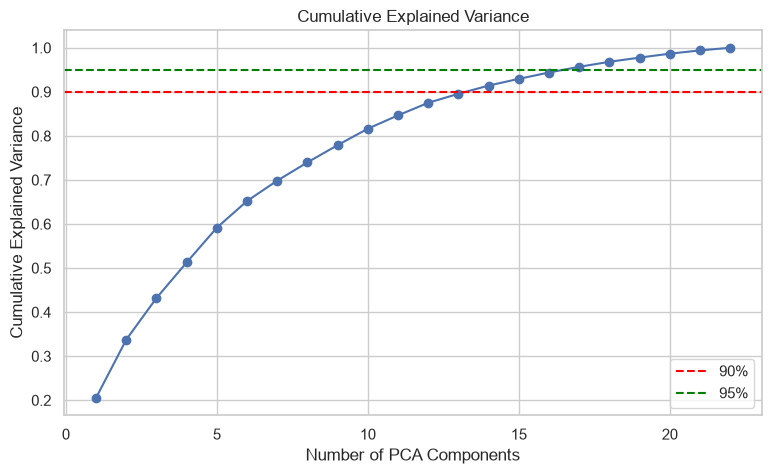

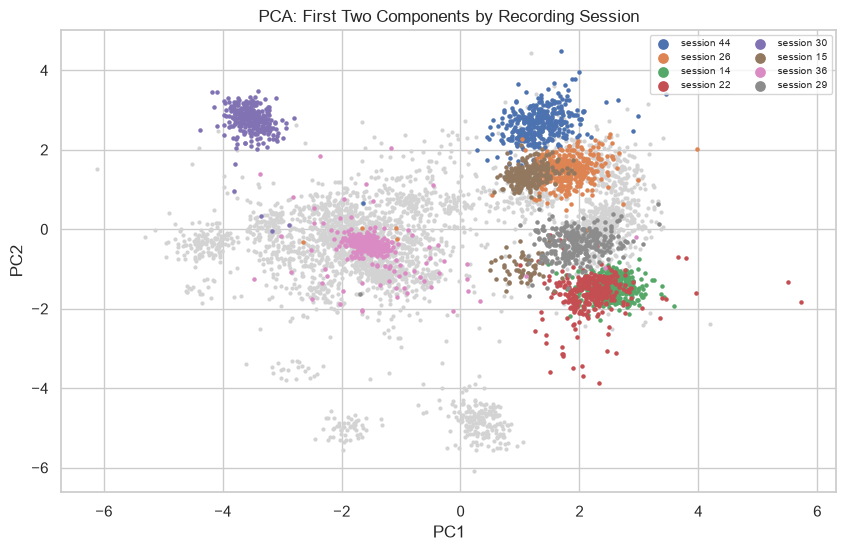

In [34]:

# Global standardization
X_global = StandardScaler().fit_transform(df[feature_cols])

# Store recording sessions
sessions = df['recording_session'].to_numpy()

# Fit PCA
pca = PCA()
X_pca = pca.fit_transform(X_global)

# Cumulative explained variance
cum = np.cumsum(pca.explained_variance_ratio_)

n90 = np.searchsorted(cum, 0.90) + 1
n95 = np.searchsorted(cum, 0.95) + 1

print(f"Components for 90% variance: {n90}")
print(f"Components for 95% variance: {n95}")

# Plot cumulative explained variance
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(range(1, len(cum) + 1), cum, marker='o')
ax.axhline(0.90, color='red', linestyle='--', label='90%')
ax.axhline(0.95, color='green', linestyle='--', label='95%')

ax.set(
    title='Cumulative Explained Variance',
    xlabel='Number of PCA Components',
    ylabel='Cumulative Explained Variance'
)
ax.legend()
plt.show()

# Plot first two PCA components by recording session
fig, ax = plt.subplots(figsize=(10, 6))

plot_sessions(
    ax,
    X_pca[:, :2],
    sessions,
    'PCA: First Two Components by Recording Session'
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

plt.show()


<details><summary><b>Hint 1</b></summary>

`np.searchsorted(cum, .90) + 1` is the number of components that reach 90%.

</details>
<details><summary><b>Hint 2</b></summary>

`plot_sessions(ax, Z[:, :2], sessions, 'title')` with `sessions = df.recording_session.to_numpy()`.

</details>

## Block 1 – Normalize by what? Microphones and recordings
Every recording reaches you through a microphone, and in MFCCs a microphone adds roughly **the same offset to every call of that recording**. Removing it is a normalization – but normalizing by the wrong thing can remove the signal itself. In this block you decide, **without any labels**, what to subtract.

### Exercise 3 – What does a global clustering follow?

Fit K-Means `k=10` on `X_global`. Report the NMI between the clusters and `recording_session`, the share of the variance that lies between sessions (`share_between`), the number of sessions in each cluster, and the median share of a session's calls that fall into its main cluster. Draw a heatmap of the share of each session's calls in each cluster.

**Explain:** The clusters follow the sessions closely. Each session is one frog – so is this clustering about frogs or about microphones? Can you tell from this exercise alone?

In [35]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`pd.crosstab(sessions, labels, normalize='index')` gives, for every session, the share of its calls in each cluster.

</details>
<details><summary><b>Hint 2</b></summary>

`pd.Series(sessions).groupby(labels).nunique()` counts the sessions in each cluster.

</details>

### Exercise 4 – Listen to the silence

Load `data/session_background.csv` as `background` and average its segments per session (`background_mean`, indexed by session). For every feature, compute the correlation **across sessions** between the session's mean call and its mean background, and the ratio between the background's and the calls' between-session variance. Plot the session means of the calls against the session means of the background for `mfcc_02` and `mfcc_05` (one point per session), and a bar chart of the 21 correlations.

**Explain:** The background contains no frog. Why do the backgrounds differ between sessions at all? What does a strong correlation between a session's calls and its silence tell you about the patches in Exercise 2?

In [36]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`background.groupby('recording_session')[feature_cols].mean()`; align the calls' session means to the same index with `.loc[background_mean.index]`.

</details>
<details><summary><b>Hint 2</b></summary>

If the silence of a session is high on `mfcc_05`, and its calls are high too, what do the calls and the silence have in common?

</details>

### Exercise 5 – Three ways to normalize – compare them before any labels

Build three matrices, each followed by `StandardScaler`:
- `X_global`: as in Exercise 2;
- `X_session`: each call minus **its own session's mean call** (per-recording mean normalization, standard in speech processing);
- `X_background`: each call minus **its session's mean background** from Exercise 4.

For each, report `share_between`, the silhouette of K-Means `k=10` (`sample_size=2000, random_state=RANDOM_STATE`) and the NMI between the clusters and `recording_session`. Store the table as `normalization_eval` and draw the first two PCA components of each with `plot_sessions`. Keep the three matrices in a dictionary `candidates`.

**Explain:** Which normalization removes the most session structure, and why is that *not* automatically the best one here? Why does the silhouette prefer the global version?

In [37]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`df.groupby('recording_session')[feature_cols].transform('mean')` gives every call its session's mean call; `background_mean.loc[sessions, feature_cols].to_numpy()` gives every call its session's background.

</details>
<details><summary><b>Hint 2</b></summary>

Each session recorded one frog. What else is in a session's mean call besides the microphone?

</details>

### Exercise 6 – Commit to a normalization

Using only the evidence so far, choose one of the three matrices for the rest of the lab and store it as `X_scaled`. Print its shape.

**Explain:** What does your choice remove, what does it keep, and what finding in Block 5 would show that you were wrong?

**Expected result (described, no picture or output is shown):** The chosen matrix stored as `X_scaled` with 6,000 rows and 21 columns, and a short justification. The rest of the expected outputs use the background normalization.

In [38]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

Use the three numbers of Exercise 5 *and* what you know about how the data was recorded.

</details>
<details><summary><b>Hint 2</b></summary>

A good justification names the assumption: what you subtract must not contain the species.

</details>

## Block 2 – Internal evaluation: K-Means
Internal metrics use only the data and the labels the model produced. They are all you have when no reference exists.

**Toolbox:** `silhouette_score` (how much closer a point is to its own cluster than to the next), `calinski_harabasz_score` (between-cluster against within-cluster spread), `davies_bouldin_score` (how similar each cluster is to its closest neighbour) and `inertia_` (the sum of squared distances to the centres).

### Exercise 7 – Build a multi-metric K-Means evaluation table

For `k = 2, ..., 12`, fit K-Means on `X_scaled` and build a DataFrame `kmeans_eval` with the inertia, the silhouette (`sample_size=2000, random_state=RANDOM_STATE`), the Calinski–Harabasz score and the Davies–Bouldin score.

**Before running the code**, write which direction is better for each metric (higher or lower).

In [39]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

Fit once per k, keep `km.labels_`, and compute all four numbers from the same labels.

</details>
<details><summary><b>Hint 2</b></summary>

Append a dictionary per k to a list, then `pd.DataFrame(rows)`.

</details>

### Exercise 8 – Visualize metric disagreement

Plot the four metrics against `k` and print the `k` that each of silhouette, Calinski–Harabasz and Davies–Bouldin prefers.

**Explain:** Do the metrics agree? Give at least **two reasons** why they can disagree.

In [40]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`plt.subplots(2, 2)` and one metric per panel.

</details>
<details><summary><b>Hint 2</b></summary>

`kmeans_eval.loc[kmeans_eval.silhouette.idxmax(), 'k']`; for Davies–Bouldin use `idxmin`.

</details>

### Exercise 9 – Look inside the average: silhouette diagrams

Choose a **compact** and a **richer** candidate from the table (the reference uses `k=4` and `k=9`). For each, fit K-Means, compute the silhouette of every call with `silhouette_samples`, and draw a silhouette diagram: the sorted values of each cluster as a horizontal band, with the mean as a dashed line. Print the cluster sizes and the share of calls with a negative silhouette.

**Explain:** What does the diagram show that the average silhouette hides? Which of your two candidates would you keep for now, and why?

In [41]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

For cluster `g`: `vals = np.sort(s[labels == g])`, then `ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals)` and move `y0` down by the cluster's size plus a gap.

</details>
<details><summary><b>Hint 2</b></summary>

A negative silhouette means a call is closer, on average, to another cluster than to its own.

</details>

## Block 3 – Stability: does the answer survive re-running?
A model you can't reproduce is hard to trust. But a reproducible answer isn't necessarily a useful one, and that difference is the point of this block.

### Exercise 10 – Measure clustering stability

For `k` in `{3, 4, 5, 9, 10}`, run K-Means **10 times** with `n_init=1` and random states `0, ..., 9`. For each `k`, report the mean and standard deviation of the inertia, and the mean and minimum pairwise ARI between the 10 clusterings. Store the table as `stability_eval`.

**Note:** here ARI compares *two clusterings with each other*, not a clustering with a reference.

In [42]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`combinations(label_runs, 2)` gives the 45 pairs of runs.

</details>
<details><summary><b>Hint 2</b></summary>

`n_init=1` is what makes the runs differ: each run starts from one random set of centres.

</details>

### Exercise 11 – Separate stability from quality

Interpret the stability table together with the internal metrics. Is the `k` with the best silhouette automatically the most stable? Is the most stable solution automatically the most meaningful? Use your actual numbers.

**Expected result (described, no picture or output is shown):** A reasoned answer that uses numbers from your stability and metric tables.

In [43]:
# Write your answer in a comment, or in a new Markdown cell

<details><summary><b>Hint 1</b></summary>

Compare the ranking of k by silhouette with the ranking by mean pairwise ARI.

</details>
<details><summary><b>Hint 2</b></summary>

What would a perfectly repeatable but too coarse clustering be good for?

</details>

## Block 4 – Other algorithms: GMM, Ward and DBSCAN
K-Means is one view. A Gaussian mixture gives a likelihood, Ward builds a hierarchy, and DBSCAN refuses to label sparse calls. Each one changes what "a good clustering" can mean.

**AIC and BIC** both reward fit and penalize parameters; lower is better, and BIC's penalty is heavier when there are many observations.

### Exercise 12 – Compare model complexity with AIC and BIC

Create an 8-component PCA representation `X_pca8` of `X_scaled` (`random_state=RANDOM_STATE`). For `n_components = 2, ..., 12`, fit a **full-covariance** `GaussianMixture` (`n_init=2, reg_covar=1e-5, random_state=RANDOM_STATE`) and record AIC and BIC in `gmm_ic`. Plot both and print each criterion's minimum.

**Explain:** Why can't you compare a BIC value with a silhouette score? Why should a minimum at the edge of the tested range make you cautious?

In [44]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`gmm.aic(X_pca8)` and `gmm.bic(X_pca8)` after `gmm.fit(X_pca8)`.

</details>
<details><summary><b>Hint 2</b></summary>

BIC has no fixed range and depends on the data it was computed on.

</details>

### Exercise 13 – A hierarchy: the Ward dendrogram

Draw a reproducible subset of **2,500 rows** with `np.sort(np.random.default_rng(RANDOM_STATE).choice(len(df), 2500, replace=False))` and store it as `subset_idx`. Build a Ward linkage on `X_pca8[subset_idx]` with `scipy.cluster.hierarchy.linkage` and draw the dendrogram of the last 30 merges. Next to it, plot the merge height against the number of clusters you would get by cutting just below it (2 to 16), and print the three largest jumps.

**Explain:** Where would you cut the tree, and how many clusters does that give? Does the hierarchy suggest one natural number of clusters?

In [45]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`dendrogram(Z_link, truncate_mode='lastp', p=30, no_labels=True, ax=ax)`.

</details>
<details><summary><b>Hint 2</b></summary>

`heights = Z_link[::-1, 2]`: `heights[0]` is the last merge (2 clusters → 1). A big drop from `heights[i]` to `heights[i + 1]` means cutting between them leaves `i + 2` well-separated clusters.

</details>

### Exercise 14 – DBSCAN: density, noise and coverage

On `X_pca8`, compute each call's distance to its 20th **other** nearest neighbour and plot the sorted distances. Run DBSCAN with `min_samples=20` and `eps` at the 50th, 65th, 80th and 90th percentiles of those distances; store the labels in `db_labels[quantile]` and build `dbscan_eval` with the number of clusters (without `-1`), the noise percentage and the silhouette **on the kept rows** (`sample_size=2000`). Plot the cluster count and the noise against the quantile.

**Explain:** What happens as `eps` grows? Why does a silhouette on the kept rows not describe the whole dataset?

In [46]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`NearestNeighbors(n_neighbors=20).fit(X_pca8).kneighbors()` without arguments leaves each row itself out.

</details>
<details><summary><b>Hint 2</b></summary>

`kept = labels != -1`; `-1` is not a cluster, it is DBSCAN refusing to label a row.

</details>

### Exercise 15 – Compare algorithms before seeing any labels

On the same 2,500 rows of `X_pca8` (`Xp_sub = X_pca8[subset_idx]`), compare K-Means, a full-covariance GMM (`n_init=2, reg_covar=1e-5`) and Ward (`AgglomerativeClustering(linkage='ward')`) at `k = 4` and `k = 9`, and DBSCAN at the 65th-percentile radius from Exercise 14 (its labels on the same rows). Build `algorithm_internal` with the coverage, silhouette (`sample_size=1500`), Calinski–Harabasz and Davies–Bouldin – for DBSCAN on its kept rows only.

**Explain:** Imagine the taxonomy file does not exist. Which algorithm and configuration would you deploy, based on internal quality, stability or complexity evidence, and simplicity?

In [47]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

Write a small function that takes labels and returns the three scores, so every algorithm is scored the same way.

</details>
<details><summary><b>Hint 2</b></summary>

DBSCAN's row: `db_sub = db_labels[.65][subset_idx]`, scored on `db_sub != -1`.

</details>

## Block 5 – Reveal the taxonomy: external evaluation
From this point on you may open `frog_taxonomy_reveal.csv`. It holds **three nested levels** of taxonomy, which were hidden until now so that they couldn't influence your choices.

**Toolbox:** ARI (agreement between two partitions, corrected for chance), NMI (shared information on a 0–1 scale) and purity. ARI and NMI ignore what the clusters are called.

### Exercise 16 – Reveal and validate the reference labels

Load `data/frog_taxonomy_reveal.csv` and merge it with `df` on `sample_id` (`validate='one_to_one'`) into `df_labeled`. Report the number of families, genera and species, the share of the largest and the smallest species, and the largest number of species in any one session. Store the species as `y_species` and plot the number of calls per species.

In [48]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`validate='one_to_one'` raises an error if a `sample_id` appears twice – which is why Exercise 1 dropped the duplicates.

</details>
<details><summary><b>Hint 2</b></summary>

`df_labeled.groupby('recording_session').species_group.nunique().max()`.

</details>

### Exercise 17 – Was your normalization right?

For each matrix in `candidates`, fit K-Means `k=10` and compute the species ARI and NMI and the NMI with `recording_session`. Show them next to the label-free columns of `normalization_eval` from Exercise 5.

**Explain:** Did the label-free evidence of Block 1 lead to the right choice? Which label-free number would have misled you?

In [49]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

Build a small table per normalization and merge it with `normalization_eval` on the `normalization` column.

</details>
<details><summary><b>Hint 2</b></summary>

Compare the ranking by silhouette with the ranking by species ARI.

</details>

### Exercise 18 – Why "adjusted"? Rand index, mutual information and entropy

Fit K-Means `k=10` on `X_scaled` and call the labels `lab10`. Make a **completely random labeling** with 10 groups (`np.random.default_rng(RANDOM_STATE).integers(0, 10, len(df))`). For both against `y_species`, print the raw Rand index (`rand_score`), ARI, raw mutual information (`mutual_info_score`) and NMI. Also print the entropy of the species and of `lab10` (`scipy.stats.entropy` on their proportions), and compare it with `ln 10`.

**Explain:** What score does a random labeling get on each measure? Why do we use the adjusted or normalized versions? What does the species entropy say about the classes?

In [50]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`entropy(y_species.value_counts(normalize=True))`.

</details>
<details><summary><b>Hint 2</b></summary>

For 10 equally large groups the entropy would be `np.log(10)`.

</details>

### Exercise 19 – Evaluate against three ground truths

For K-Means with `k = 2, ..., 12` on `X_scaled`, compute ARI and NMI against each taxonomy level and store them in one table `external_eval`. Plot NMI and ARI against `k` (one panel each, three lines), and print the best `k` for each level and each score.

**Explain:** Compare the best `k` values with the number of groups at each level and with the internally preferred `k` from Block 2. Why can ARI and NMI prefer different `k`?

In [51]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

Loop over `k`, fit once, then loop over the three levels: `df_labeled[f'{level}_group']`.

</details>
<details><summary><b>Hint 2</b></summary>

ARI counts *pairs* of calls. Which species contributes most of the pairs?

</details>

### Exercise 20 – Inspect where the score comes from

For `lab10`, draw the contingency table of clusters against `y_species` as an annotated heatmap. Map every cluster to its **most common species** (a many-to-one mapping), report the purity (the accuracy of that mapping) and the species that are the majority of no cluster, and print a `classification_report` of the mapped labels (`zero_division=0`).

**Explain:** Find one species split across several clusters and one species that is never a majority. Why can purity be high while some species are never recovered?

In [52]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`ct.idxmax(axis=1)` gives each cluster's majority species; `pd.Series(lab10).map(majority)` gives a predicted species per call.

</details>
<details><summary><b>Hint 2</b></summary>

Purity rewards every cluster for its majority. Can a small species be the majority anywhere?

</details>

### Exercise 21 – Look at the map

On the 2,500 rows of `subset_idx`, fit a 2D t-SNE of `X_scaled` (`perplexity=40, init='pca', learning_rate='auto', random_state=RANDOM_STATE, **TSNE_ITER`). Draw three panels of the same map, coloured by `lab10`, by species, and by session (`plot_sessions`). Print the NMI of `lab10` with the species and with the session on these rows.

**Explain:** What are the islands of the map made of – clusters, species or sessions? What does that mean for a clustering of *new* recordings?

In [53]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

For the species panel, loop over the species and scatter each one with its own label.

</details>
<details><summary><b>Hint 2</b></summary>

t-SNE keeps each call's nearest neighbours close. Who are a call's nearest neighbours, most of the time?

</details>

## Block 6 – Leakage and new recording sessions
So far, higher scores have looked like good news. This block is about when they aren't – and about testing the model the way it will be used: on recordings it has never heard.

### Exercise 22 – Test the recording-session metadata trap

Repeat K-Means `k=10`, but this time **incorrectly add `recording_session` as a numeric feature** to the background-subtracted calls, and standardize everything together. Compare the correct and the incorrect model by silhouette, species ARI and species NMI.

**Explain:** Did the wrong feature make the scores better or worse, and why is that dangerous?

In [54]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

`np.column_stack([background-subtracted calls, sessions])`, then `StandardScaler`.

</details>
<details><summary><b>Hint 2</b></summary>

Each session holds one species. What can a session number tell the model about the answer?

</details>

### Exercise 23 – Evaluate on unseen sessions

Use `GroupShuffleSplit(n_splits=5, test_size=0.25, random_state=RANDOM_STATE)` with the sessions as groups, so that whole sessions are held out. For every split and every normalization (`global`, `session mean`, `background`): fit the scaler and K-Means `k=10` **on the training rows only**, predict the held-out rows, and compute the species ARI and NMI. Report the mean and standard deviation per normalization and plot the ARI of every split. Keep the first split's `train_idx` and `test_idx`.

**Explain:** Is each normalization usable on a new recording? How large is the difference between normalizations compared with the variation between splits?

In [55]:
# Write your code here

<details><summary><b>Hint 1</b></summary>

Build the three *unscaled* inputs first (raw, minus session mean, minus background); fit `StandardScaler` inside the loop on `M[train_idx]`.

</details>
<details><summary><b>Hint 2</b></summary>

A new session comes with its own background segments and its own calls, so both subtractions can be computed for it without any label.

</details>

### Exercise 24 – Recognize grouped data

Why is a group-based split more informative than a random split of individual calls, when many calls come from the same recording session? Give one example of another dataset where the same principle applies.

**Expected result (described, no picture or output is shown):** An explanation and one example from another domain.

In [56]:
# Write your answer in a comment, or in a new Markdown cell

<details><summary><b>Hint 1</b></summary>

With a random split, where do the other calls of a test call's recording end up?

</details>
<details><summary><b>Hint 2</b></summary>

Think of repeated measurements of the same patient, user, machine or video.

</details>

## Block 7 – Find the bug
Three checks. In all of them the code **runs without an error** and the conclusion is still wrong.

**How to hunt a silent bug:** (1) compare the result with a number you trust; (2) ask what the score actually measures; (3) ask what would have to be true for this comparison to be fair.

### Exercise 25 – Only 0.5% accurate?

A colleague scores your k=10 clustering against the species and reports: *"The clustering is less than 1% accurate, so it is useless."* Show what is wrong, give the agreement with appropriate scores, and compute the accuracy **after** matching each cluster to one species (`linear_sum_assignment` on the crosstab).

**Expected result (described, no picture or output is shown):** The raw accuracy, ARI and NMI, the accuracy after a one-to-one matching, the purity from Exercise 20, and one sentence on why the first number means nothing.

In [57]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.

species_codes = df_labeled['species_group'].astype('category').cat.codes
print('Accuracy:', round((species_codes == lab10).mean(), 3))

NameError: name 'df_labeled' is not defined

<details><summary><b>Hint 1</b></summary>

Does cluster 3 have anything to do with the third species in alphabetical order?

</details>
<details><summary><b>Hint 2</b></summary>

`linear_sum_assignment(table, maximize=True)` pairs each cluster with a different species so that the matched counts are as large as possible.

</details>

### Exercise 26 – Perfectly stable!

A colleague tests the stability of k=10 and reports: *"ARI between runs is 1.000, so k=10 is perfectly stable."* Find the bug and give the honest number.

**Expected result (described, no picture or output is shown):** The ARI between two different seeds, the mean pairwise ARI from your stability table, and a one-sentence correction.

In [ ]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.

run_a = KMeans(n_clusters=10, n_init=1, random_state=0).fit_predict(X_scaled)
run_b = KMeans(n_clusters=10, n_init=1, random_state=0).fit_predict(X_scaled)
print('ARI between runs:', round(adjusted_rand_score(run_a, run_b), 3))

<details><summary><b>Hint 1</b></summary>

What is different between the two runs?

</details>
<details><summary><b>Hint 2</b></summary>

A stability test has to change something between runs.

</details>

### Exercise 27 – The microphones don't matter?

A colleague tries the background correction and reports: *"Subtracting the background barely changes the clustering – the NMI with the session only drops from 0.71 to 0.69 – so the microphones don't matter."* Find the bug and give the honest comparison.

**Expected result (described, no picture or output is shown):** For global standardization, the colleague's pipeline and the correct background pipeline: the share of variance between sessions, the NMI with the session and the species ARI of K-Means `k=10`; then one sentence on the bug.

In [ ]:
# This code runs without an error but gives a wrong result. Find the bug, explain it, fix it.

X_std = StandardScaler().fit_transform(df[feature_cols])
X_bug = X_std - background_mean.loc[sessions, feature_cols].to_numpy()
labels = KMeans(10, n_init=20, random_state=RANDOM_STATE).fit_predict(X_bug)
print('NMI with session:', round(normalized_mutual_info_score(sessions, labels), 3))
# Conclusion: subtracting the background barely changes anything, so the microphones don't matter.

<details><summary><b>Hint 1</b></summary>

In which units is `X_std`, and in which units is `background_mean`?

</details>
<details><summary><b>Hint 2</b></summary>

Subtract first, in the units the background was measured in, and standardize afterwards.

</details>

## Block 8 – Integrated challenge: the evaluation report
**The task.** The biologists ask: *which model should we use to sort new recordings by species, and how far can we trust it?* Answer them with evidence from all the earlier blocks.

### Exercise 28 – Write the evaluation report

Write a **3–5 paragraph technical conclusion** answering all of the following:

1. How should new recordings be normalized, and what evidence – before and after the labels – supports it?
2. Which `k` and which algorithm looked best before the labels were revealed, and why?
3. How did the answer change when the family, genus and species labels were revealed, and what did stability and AIC/BIC add that silhouette alone did not?
4. What did the `recording_session` experiments (the leakage trap and the held-out sessions) teach?
5. For **species sorting on new recording sessions**, which configuration would you recommend, and which limitation would you report?

Refer to **specific numbers or plots** from your notebook.

**Expected result (described, no picture or output is shown):** A 3–5 paragraph conclusion that answers all five questions and cites specific numbers from your notebook.

In [ ]:
# Write your answer in a comment, or in a new Markdown cell

<details><summary><b>Hint 1</b></summary>

Start from the normalization: everything after it depends on it.

</details>
<details><summary><b>Hint 2</b></summary>

Every claim gets a number: a score, a share, a count of sessions.

</details>

## Block 9 – Working with an LLM, critically
You may use ChatGPT, Claude, Gemini or Copilot in this course. The rule is: **you are responsible for every line and every claim**. Below are two prompts, each with a typical answer. The code runs, the output looks reasonable, and each answer is wrong in several ways that only the data can reveal.

For each exercise, do four things: (a) copy the model's code into a new cell and run it, to see its output; (b) find what is wrong, and print **a number from the data that proves each problem**; (c) in the cell below, write the corrected code; (d) write in a comment the one lesson you take from it.

### Exercise 29 – LLM answer 1: how many species?

**Prompt:** *"Here is `frog_calls.csv`. How many frog species are in this file?"*

The model's answer is shown below. **Run it in a new cell.** Find **at least three** flaws, and for each one print a number that proves it (for example: which columns it used, what controls its distances, what its clusters agree with). Then write a corrected version.

**Expected result (described, no picture or output is shown):** Printed numbers that prove at least three flaws, each with a short comment, followed by a corrected result.

**Typical LLM answer. Copy it into a new cell and run it, to see its output. It reads the raw file again, so it does not use your tables; do not trust its result:**

```python
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

raw = pd.read_csv('data/frog_calls.csv')
numeric = raw.select_dtypes('number')
scores = {k: silhouette_score(numeric, KMeans(k, n_init=10, random_state=42).fit_predict(numeric),
                              sample_size=2000, random_state=42) for k in range(2, 13)}
print({k: round(v, 3) for k, v in scores.items()})
print('Best k:', max(scores, key=scores.get))
# Conclusion: the highest silhouette tells us how many species there are in this file.
```

In [ ]:
# Corrected version – write your code here

<details><summary><b>Hint 1</b></summary>

Print `numeric.columns` and `numeric.var() / numeric.var().sum()`. Which column decides the distances?

</details>
<details><summary><b>Hint 2</b></summary>

How many rows does `raw` have, and how many did you keep in Exercise 1?

</details>
<details><summary><b>Hint 3</b></summary>

Compare its clusters with `recording_session` and with the species.

</details>

### Exercise 30 – LLM answer 2: standard audio normalization and a clean test set

**Prompt:** *"I want to know if my frog clustering will work on future recordings. Use the standard audio normalization and evaluate it properly with a test set."*

The model's answer is shown below; it continues from your notebook and uses `df` and `y_species`. **Run it in a new cell.** Explain **what is wrong with it statistically** and with its conclusion, and print a number that proves each problem. Then write the corrected version.

**Expected result (described, no picture or output is shown):** Printed numbers that show the effect of the normalization, the session overlap between training and test, and the honest held-out result; then a sentence on what can and cannot be concluded.

**Typical LLM answer. Copy it into a new cell and run it, to see its output. It continues from your notebook and uses your `df` and `y_species`; do not trust its result:**

```python
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feats = [c for c in df.columns if c.startswith('mfcc_')]
# Cepstral mean normalization: the standard way to remove microphone effects from audio features.
X_cmn = StandardScaler().fit_transform(df[feats] - df.groupby('recording_session')[feats].transform('mean'))
X_tr, X_te, y_tr, y_te = train_test_split(X_cmn, y_species, test_size=0.25, random_state=42)
best = max(range(2, 13), key=lambda k: adjusted_rand_score(y_te, KMeans(k, n_init=10, random_state=42).fit(X_tr).predict(X_te)))
model = KMeans(best, n_init=10, random_state=42).fit(X_tr)
print('Best k:', best, '| Test ARI:', round(adjusted_rand_score(y_te, model.predict(X_te)), 3))
# Conclusion: microphone effects are removed and this is a clean test score, so we know how well it will work on future recordings.
```

In [ ]:
# Corrected version – write your code here

<details><summary><b>Hint 1</b></summary>

Each recording holds one frog. What does subtracting a recording's mean call remove besides the microphone?

</details>
<details><summary><b>Hint 2</b></summary>

How many test sessions also appear in training with a random row split?

</details>
<details><summary><b>Hint 3</b></summary>

Which data chose `best`?

</details>

## Block 10 – Further investigations ★ (extra)
Every exercise in this block is marked with ★: they are extra, for whoever finishes early.

### Exercise 31 – Do AIC and BIC find the species? ★

For `k` in `3, 5, 10, 12`, fit the same GMM as in Exercise 12 on `X_pca8` and K-Means on `X_scaled`, and compare their species ARI and NMI in one table.

**Explain:** AIC and BIC preferred k=12. Is the GMM there better at finding species than K-Means, or than a smaller GMM? What does that say about using BIC to answer the biologists' question?

In [ ]:
# Write your code here

,k,ARI_GMM,ARI_KMeans,NMI_GMM,NMI_KMeans
0,3,0.642,0.659,0.552,0.565
1,5,0.431,0.831,0.546,0.680
2,10,0.531,0.441,0.665,0.647
3,12,0.432,0.410,0.663,0.625


<details><summary><b>Hint 1</b></summary>

Reuse the GMM settings of Exercise 12: `covariance_type='full', n_init=2, reg_covar=1e-5`.

</details>
<details><summary><b>Hint 2</b></summary>

Put both algorithms in one row per k.

</details>

### Exercise 32 – Evaluating DBSCAN against the taxonomy ★

For every quantile in `db_labels`, report the number of clusters, the coverage, and the species ARI and NMI **on the kept rows only**, together with the NMI with `recording_session` on the same rows and the smallest share of any species that DBSCAN keeps.

**Explain:** Is a near-perfect score on the kept rows a reason to prefer DBSCAN? What would you report next to it?

In [ ]:
# Write your code here

,quantile,clusters,coverage,ARI_kept,NMI_kept,NMI_session_kept,worst_species_coverage
0,0.50,14,0.701,0.993,0.957,0.615,0.004
1,0.65,14,0.788,0.966,0.903,0.628,0.106
2,0.80,13,0.892,0.923,0.848,0.605,0.411
3,0.90,2,0.954,0.011,0.027,0.028,0.732


<details><summary><b>Hint 1</b></summary>

`kept = labels != -1`, then score `y_species[kept]` against `labels[kept]`.

</details>
<details><summary><b>Hint 2</b></summary>

`pd.Series(kept).groupby(y_species.to_numpy()).mean().min()` is the coverage of the worst-covered species.

</details>

### Exercise 33 – Can BIC choose the representation? ★

A colleague wants to choose how many PCA components to keep for the GMM and argues: *"BIC is much lower with 3 components than with 8, so 3 is the better representation."* For 8, 5, 3, 2 and 1 components, fit a 10-component GMM (settings of Exercise 12) and report its BIC and its species NMI.

**Explain:** Why can't BIC compare models fitted to different data?

In [ ]:
# Write your code here

,components,BIC,NMI_species
0,8,104281,0.665
1,5,78728,0.655
2,3,59533,0.554
3,2,44357,0.562
4,1,23068,0.493


<details><summary><b>Hint 1</b></summary>

Refit PCA with `n_components=n` each time, then the GMM on that representation.

</details>
<details><summary><b>Hint 2</b></summary>

BIC is the likelihood of *the data it was given*. Is a table with fewer columns the same data?

</details>

# **Good Job :)**

Before you submit: make sure every cell runs top to bottom (Kernel ▸ Restart & Run All), and check that the PDF shows the same figures, tables and reasoning as the notebook.